In [1]:
import numpy as np
import pandas as pd
import torch

from transformers import BertTokenizer
from sklearn.preprocessing import LabelEncoder

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [6]:
artifact_path = '/content/drive/MyDrive/Emotion_Classification/Artifacts'

In [2]:
!pip install transformers tensorflow
import tensorflow as tf

from transformers import AutoTokenizer
from transformers import TFAutoModelForSequenceClassification

In [3]:
from datasets import load_dataset

emotion_dataset = load_dataset('dair-ai/emotion')

train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']
train_text = list(train_text)
test_text = list(test_text)

label_names = emotion_dataset['train'].features['label'].names

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [4]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
val_text = list(emotion_dataset['validation']['text'])
val_label = emotion_dataset['validation']['label']

Tokenizer

In [6]:
model_name = "google-bert/bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [7]:
max_length = 128

train_encodings = tokenizer(
    train_text,
    truncation=True,
    padding='max_length',
    max_length=max_length,
    return_tensors='tf'
)

val_text = list(emotion_dataset['validation']['text'])
val_label = emotion_dataset['validation']['label']

val_encodings = tokenizer(
    val_text,
    truncation=True,
    padding='max_length',
    max_length=max_length,
    return_tensors='tf'
)

test_encodings = tokenizer(
    test_text,
    truncation=True,
    padding='max_length',
    max_length=max_length,
    return_tensors='tf'
)

In [8]:
train_inputs = dict(train_encodings)
val_inputs = dict(val_encodings)
test_inputs = dict(test_encodings)

In [9]:
train_labels = tf.constant(train_label)
val_labels = tf.constant(val_label)
test_labels = tf.constant(test_label)


In [11]:
batch_size = 16

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_inputs, train_labels)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_inputs, val_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_inputs, test_labels)
)
train_dataset = train_dataset.shuffle(1000).batch(batch_size)

val_dataset = val_dataset.batch(batch_size)

test_dataset = test_dataset.batch(batch_size)

Model: BERT

In [12]:
from transformers import TFAutoModelForSequenceClassification

In [13]:
num_classes = len(label_names)

BERT_model = TFAutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_classes
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

All PyTorch model weights were used when initializing TFBertForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [15]:
BERT_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [18]:
from tf_keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [19]:
history = BERT_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
1000/1000 [==============================] - 517s 469ms/step - loss: 0.4752 - accuracy: 0.8308 - val_loss: 0.1821 - val_accuracy: 0.9360
Epoch 2/5
1000/1000 [==============================] - 465s 465ms/step - loss: 0.1352 - accuracy: 0.9413 - val_loss: 0.1438 - val_accuracy: 0.9300
Epoch 3/5
1000/1000 [==============================] - 461s 461ms/step - loss: 0.0987 - accuracy: 0.9507 - val_loss: 0.1530 - val_accuracy: 0.9365
Epoch 4/5
1000/1000 [==============================] - 461s 461ms/step - loss: 0.0920 - accuracy: 0.9541 - val_loss: 0.1475 - val_accuracy: 0.9345


Evaluation

In [20]:
BERT_loss, BERT_accuracy = BERT_model.evaluate(test_dataset)

print(f"BERT Loss: {BERT_loss}")
print(f"BERT Accuracy: {BERT_accuracy}")

125/125 [==============================] - 20s 158ms/step - loss: 0.1380 - accuracy: 0.9325
BERT Loss: 0.1379990577697754
BERT Accuracy: 0.9325000047683716


In [21]:
BERT_predictions = BERT_model.predict(test_dataset)
BERT_predictions = np.argmax(BERT_predictions.logits, axis=1)

125/125 [==============================] - 23s 160ms/step


In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    test_label,
    BERT_predictions,
    target_names=label_names
))

              precision    recall  f1-score   support

     sadness       0.98      0.97      0.97       581
         joy       0.98      0.91      0.94       695
        love       0.76      0.96      0.85       159
       anger       0.93      0.92      0.93       275
        fear       0.87      0.97      0.92       224
    surprise       0.93      0.62      0.75        66

    accuracy                           0.93      2000
   macro avg       0.91      0.89      0.89      2000
weighted avg       0.94      0.93      0.93      2000



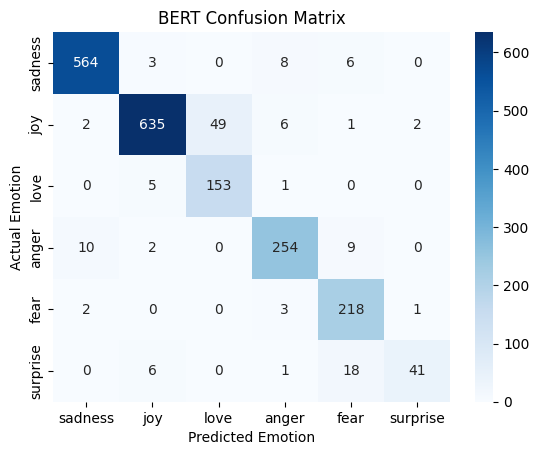

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(test_label, BERT_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_names,
    yticklabels=label_names
)

plt.xlabel('Predicted Emotion')
plt.ylabel('Actual Emotion')
plt.title('BERT Confusion Matrix')
plt.show()

Test on sample

In [24]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]
sample_encodings = tokenizer(
    sample_texts,
    truncation=True,
    padding='max_length',
    max_length=128,
    return_tensors='tf'
)

In [25]:
sample_predictions = BERT_model.predict(dict(sample_encodings))

sample_classes = np.argmax(sample_predictions.logits, axis=1)

1/1 [==============================] - 3s 3s/step


In [26]:
for i in range(len(sample_texts)):
    print(
        f"Text: {sample_texts[i]}\n"
        f"Predicted Emotion: {label_names[sample_classes[i]]}\n"
    )

Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy

Text: I feel so alone and hopeless today.
Predicted Emotion: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise



In [27]:
import pandas as pd

comparison_df = pd.DataFrame({
    'Model': ['BiGRU', 'BERT'],
    'Test Loss': [0.2278, BERT_loss],
    'Test Accuracy': [0.9175, BERT_accuracy]
})

comparison_df

,Model,Test Loss,Test Accuracy
0,BiGRU,0.227800,0.9175
1,BERT,0.137999,0.9325


In [28]:
import os

bert_dir = '/content/drive/MyDrive/Emotion_Classification/Artifacts/BERT'

os.makedirs(bert_dir, exist_ok=True)

# Save fine-tuned BERT model
BERT_model.save_pretrained(bert_dir)

# Save BERT tokenizer
tokenizer.save_pretrained(bert_dir)

print("BERT model and tokenizer saved successfully!")

BERT model and tokenizer saved successfully!


In [29]:
import os

bert_dir = '/content/drive/MyDrive/Emotion_Classification/Artifacts'

# Save BERT model
BERT_model.save_pretrained(bert_dir)

# Save BERT tokenizer
tokenizer.save_pretrained(bert_dir)

print("BERT saved successfully!")

BERT saved successfully!
